# AI 14 - Ev tapşırığı
# Neyron şəbəkələrinin əsasları - konspekt
PyTorch, Loss funksiyaları, Softmax və Cross Entropy, Optimizer-lər

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(42)
print(torch.__version__)

2.2.2


# 1. PyTorch və neyron şəbəkələri

## PyTorch nədir?
PyTorch - Meta (Facebook) tərəfindən hazırlanmış açıq mənbəli deep learning kitabxanasıdır.

**Nə üçün istifadə olunur:**
- **Tensor** ilə işləmək - NumPy massivinə oxşayır, amma GPU-da da hesablana bilir
- **Autograd** - törəmələri (gradient) avtomatik hesablayır, backpropagation-u əl ilə yazmırıq
- **torch.nn** - hazır qatlar, aktivasiya və loss funksiyaları
- **torch.optim** - hazır optimizer-lər (SGD, Adam və s.)
- **DataLoader** - datanı batch-lərlə vermək

Kompüter görmə (şəkil tanıma), mətn (NLP), səs və s. üçün modellər PyTorch ilə yazılır.

## Neyron şəbəkəsi (NN) nədir?
Neyron şəbəkəsi bir-birinə bağlı neyronlardan ibarət modeldir. Hər neyron girişləri çəkilərə vurub toplayır, bias əlavə edir və aktivasiya funksiyasından keçirir:

$$
z = w_1x_1 + w_2x_2 + ... + w_nx_n + b, \quad a = f(z)
$$

Neyronlar qatlarda (layer) yerləşir:
- **Input layer** - giriş əlamətləri (məs. MNIST-də 784 piksel)
- **Hidden layer(s)** - gizli qatlar, datadakı asılılıqları öyrənir
- **Output layer** - nəticə (reqressiyada 1 ədəd, təsnifatda hər sinif üçün bir ədəd)

Aktivasiya funksiyası (ReLU, Sigmoid, Tanh) olmasa, neçə qat olsa da şəbəkə sadəcə xətti model olardı. Qeyri-xəttiliyi aktivasiya verir.

Öyrənmə dövrü: **forward** (proqnoz) → **loss** (səhv) → **backward** (gradientlər) → **optimizer step** (çəkiləri yeniləmək).

## torch.nn, nn.Module, nn.Linear

**torch.nn** - neyron şəbəkəsi qurmaq üçün modul: qatlar (`nn.Linear`, `nn.Conv2d`), aktivasiyalar (`nn.ReLU`), loss-lar (`nn.MSELoss`, `nn.CrossEntropyLoss`).

**nn.Module** - bütün modellərin və qatların əsas (baza) sinfidir. Öz modelimizi yazanda ondan miras alırıq:
- `__init__`-də qatları yaradırıq
- `forward`-da datanın qatlardan necə keçdiyini yazırıq
- `model.parameters()` bütün öyrədilən çəkiləri qaytarır (optimizer-ə bunu veririk)

**nn.Linear(in_features, out_features)** - tam bağlı (fully connected) qat:

$$
y = xW^T + b
$$

`weight` ölçüsü `(out_features, in_features)`, `bias` ölçüsü `(out_features)`. Çəkilər təsadüfi başlanır və `requires_grad=True` olur.

In [2]:
layer = nn.Linear(4, 3)
print(layer.weight.shape)
print(layer.bias.shape)
print(layer.weight.requires_grad)

torch.Size([3, 4])
torch.Size([3])
True


In [3]:
x = torch.randn(5, 4)
y = layer(x)
print(y.shape)

torch.Size([5, 3])


In [4]:
y_manual = x @ layer.weight.T + layer.bias
print(torch.allclose(y, y_manual))

True


## forward() metodu

`forward()` modelin giriş datanı nəticəyə necə çevirdiyini göstərir (forward propagation). `model(x)` yazanda PyTorch `__call__` vasitəsilə `forward(x)`-i özü çağırır, ona görə `model.forward(x)` yox, `model(x)` yazırıq.

`backward()` metodunu yazmırıq - autograd forward-da edilən əməliyyatları yadda saxlayır (hesablama qrafı) və gradientləri özü hesablayır.

In [5]:
class Net(nn.Module):
    def __init__(self, in_features, hidden, out_features):
        super().__init__()
        self.fc1 = nn.Linear(in_features, hidden)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden, out_features)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x


model = Net(4, 8, 3)
print(model)

Net(
  (fc1): Linear(in_features=4, out_features=8, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=8, out_features=3, bias=True)
)


In [6]:
for name, p in model.named_parameters():
    print(name, tuple(p.shape))

print("Parametr sayı:", sum(p.numel() for p in model.parameters()))

fc1.weight (8, 4)
fc1.bias (8,)
fc2.weight (3, 8)
fc2.bias (3,)
Parametr sayı: 67


In [7]:
out = model(x)
print(out.shape)
print(out[0])

torch.Size([5, 3])
tensor([ 0.2201, -0.0457, -0.2655], grad_fn=<SelectBackward0>)


4·8 + 8 = 40 və 8·3 + 3 = 27, cəmi 67 parametr. Çıxışda hər nümunə üçün 3 ədəd var - bunlar hələ ehtimal deyil, **logit**-dir (softmax-dan əvvəlki xam dəyərlər).

Eyni modeli `nn.Sequential` ilə daha qısa yazmaq olar:

In [8]:
model_seq = nn.Sequential(
    nn.Linear(4, 8),
    nn.ReLU(),
    nn.Linear(8, 3)
)
print(model_seq)

Sequential(
  (0): Linear(in_features=4, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=3, bias=True)
)


# 2. Loss Functions - İtki funksiyaları

## Loss function nədir və nə üçün lazımdır?
Loss funksiyası modelin proqnozu ilə həqiqi cavab arasındakı fərqi **bir ədədlə** ölçür. Loss nə qədər kiçikdirsə, model o qədər yaxşıdır.

Nə üçün lazımdır:
- Modelin nə qədər səhv etdiyini qiymətləndirir
- Öyrənmənin məqsədi loss-u minimuma endirməkdir
- `loss.backward()` məhz bu ədəddən gradientləri hesablayır - yəni hər çəkinin loss-a təsirini tapır
- Optimizer bu gradientlərlə çəkiləri loss-u azaldan istiqamətdə dəyişir

Metrikadan fərqi: metrika (accuracy, R²) insan üçündür, loss isə optimizasiya üçündür, ona görə diferensiallana bilən olmalıdır.

## MSELoss - Mean Squared Error (reqressiya)
$$
MSE = \frac{1}{n}\sum_{i=1}^n(y_i - \hat{y_i})^2
$$
Fərqi kvadrata yüksəltdiyi üçün böyük səhvləri çox cəzalandırır. Qiymət, temperatur kimi ədədi proqnozlarda istifadə olunur.

## BCELoss - Binary Cross Entropy (ikili təsnifat)
$$
BCE = -\frac{1}{n}\sum_{i=1}^n\left[y_i\log(p_i) + (1-y_i)\log(1-p_i)\right]
$$
Cavab 0 və ya 1-dir (spam / spam deyil). Modelin çıxışı **sigmoid**-dən keçmiş ehtimal (0-1 arası) olmalıdır. Daha stabil variant `nn.BCEWithLogitsLoss` - sigmoid-i özü edir, ona logit veririk.

## CrossEntropyLoss (çox sinifli təsnifat)
$$
L = -\log(p_{k})
$$
burada $p_k$ - modelin düzgün sinifə verdiyi ehtimaldır. Ona softmax-dan əvvəlki **logit**-ləri və sinif nömrələrini (0, 1, 2, ...) veririk. Ətraflı 3-cü bölmədə.

| Məsələ | Loss | Son qat | Hədəf |
|---|---|---|---|
| Reqressiya | `MSELoss` | Linear, 1 çıxış | ədəd |
| İkili təsnifat | `BCELoss` / `BCEWithLogitsLoss` | 1 çıxış + sigmoid / logit | 0 və ya 1 (float) |
| Çox sinifli təsnifat | `CrossEntropyLoss` | C çıxış, logit | sinif nömrəsi (long) |

In [9]:
y_true = torch.tensor([3.0, 5.0, 2.5, 7.0])
y_pred = torch.tensor([2.5, 5.0, 4.0, 8.0])

mse = nn.MSELoss()
print("MSELoss:", mse(y_pred, y_true).item())
print("Əl ilə:", ((y_true - y_pred) ** 2).mean().item())

MSELoss: 0.875
Əl ilə: 0.875


In [10]:
y_true = torch.tensor([1.0, 0.0, 1.0, 0.0])
logits = torch.tensor([2.0, -1.0, 0.3, 1.5])
p = torch.sigmoid(logits)
print("Ehtimallar:", p)

bce = nn.BCELoss()
print("BCELoss:", bce(p, y_true).item())
print("BCEWithLogitsLoss:", nn.BCEWithLogitsLoss()(logits, y_true).item())
print("Əl ilə:", (-(y_true * torch.log(p) + (1 - y_true) * torch.log(1 - p))).mean().item())

Ehtimallar: tensor([0.8808, 0.2689, 0.5744, 0.8176])
BCELoss: 0.6739895343780518
BCEWithLogitsLoss: 0.6739895939826965
Əl ilə: 0.6739895343780518


Səhvin qiymətləndirilməsi: düzgün cavaba inamla doğru proqnoz kiçik loss, inamla səhv proqnoz isə çox böyük loss verir.

In [11]:
for prob in [0.99, 0.9, 0.6, 0.5, 0.1, 0.01]:
    loss = bce(torch.tensor([prob]), torch.tensor([1.0])).item()
    print(f"y=1, p={prob}: BCE = {loss:.3f}")

y=1, p=0.99: BCE = 0.010
y=1, p=0.9: BCE = 0.105
y=1, p=0.6: BCE = 0.511
y=1, p=0.5: BCE = 0.693
y=1, p=0.1: BCE = 2.303
y=1, p=0.01: BCE = 4.605


# 3. Softmax və Cross Entropy

## Softmax funksiyası nədir?
Model çox sinifli təsnifatda hər sinif üçün bir ədəd (logit) qaytarır. Bu ədədlər mənfi ola bilər, cəmi 1 deyil - ehtimal deyil. Softmax onları ehtimala çevirir:

$$
P_i = \frac{e^{z_i}}{\sum_{j=1}^{C}e^{z_j}}
$$

Necə çevirir:
1. `exp` hər ədədi müsbət edir
2. Hər birini cəmə bölürük - nəticələrin cəmi 1 olur
3. Ən böyük logit ən böyük ehtimalı alır, sıra dəyişmir

Proqnoz ən böyük ehtimalı olan sinifdir: `argmax`. Softmax ancaq `dim` üzrə tətbiq olunur - batch-də hər sətir ayrı (`dim=1`).

In [12]:
z = torch.tensor([2.0, 1.0, 0.1])
p_manual = torch.exp(z) / torch.exp(z).sum()
p = F.softmax(z, dim=0)

print("Softmax:", p)
print("Əl ilə:", p_manual)
print("Cəm:", p.sum().item())
print("Sinif:", p.argmax().item())

Softmax: tensor([0.6590, 0.2424, 0.0986])
Əl ilə: tensor([0.6590, 0.2424, 0.0986])
Cəm: 1.0000001192092896
Sinif: 0


In [13]:
batch_logits = torch.tensor([[2.0, 1.0, 0.1],
                             [0.5, 2.5, -1.0]])
probs = F.softmax(batch_logits, dim=1)
print(probs)
print(probs.sum(dim=1))

tensor([[0.6590, 0.2424, 0.0986],
        [0.1161, 0.8580, 0.0259]])
tensor([1.0000, 1.0000])


## Cross Entropy nədir?
Cross Entropy iki paylanma arasındakı fərqi ölçür: həqiqi cavab (one-hot, məs. `[0, 1, 0]`) və modelin ehtimalları.

$$
H(y, p) = -\sum_{i=1}^{C} y_i\log(p_i)
$$

One-hot-da yalnız düzgün sinif 1 olduğu üçün düstur sadələşir:

$$
L = -\ln(p_k)
$$

- Düzgün sinifə ehtimal 1-ə yaxın olsa → loss 0-a yaxın
- Düzgün sinifə ehtimal 0-a yaxın olsa → loss çox böyük

## Softmax ilə Cross Entropy-nin əlaqəsi
Softmax ehtimalları verir, Cross Entropy həmin ehtimallardan düzgün sinifinkini götürüb `-log` hesablayır. Yəni ikisi birlikdə işləyir: **logit → softmax → ehtimal → cross entropy → loss**.

PyTorch-da `nn.CrossEntropyLoss` = `LogSoftmax` + `NLLLoss`. Softmax-ı **özü edir**, ona görə:
- modelin son qatında softmax yazmırıq, logit qaytarırıq
- softmax-ı ancaq proqnozda ehtimal görmək üçün ayrıca tətbiq edirik
- `log_softmax` birbaşa hesablandığı üçün daha stabildir (çox kiçik ehtimalda `log(0)` problemi olmur)

Gözəl xüsusiyyəti: softmax + cross entropy-nin logit-ə görə gradienti sadəcə $p - y$ olur.

In [14]:
logits = torch.tensor([[2.0, 1.0, 0.1],
                       [0.5, 2.5, -1.0],
                       [0.2, 0.1, 3.0]])
target = torch.tensor([0, 1, 1])

probs = F.softmax(logits, dim=1)
manual = -torch.log(probs[range(3), target]).mean()

print("Əl ilə:", manual.item())
print("CrossEntropyLoss:", nn.CrossEntropyLoss()(logits, target).item())
print("log_softmax + nll:", F.nll_loss(F.log_softmax(logits, dim=1), target).item())

Əl ilə: 1.1932698488235474
CrossEntropyLoss: 1.1932698488235474
log_softmax + nll: 1.1932698488235474


3-cü nümunədə model 2-ci sinifi seçir, düzgün cavab isə 1-dir - loss-u ən çox o artırır:

In [15]:
per_sample = nn.CrossEntropyLoss(reduction="none")(logits, target)
print(per_sample)

tensor([0.4170, 0.1532, 3.0096])


Səhv: modeldə softmax edib sonra yenə `CrossEntropyLoss` istifadə etmək (iki dəfə softmax). Ehtimallar 0-1 arasında olduğu üçün ikinci softmax onları bir-birinə yaxınlaşdırır və loss heç vaxt 0-a enmir - model tam düzgün və əmin olsa belə:

In [16]:
perfect = torch.tensor([[10.0, -10.0, -10.0],
                        [-10.0, 10.0, -10.0]])
target2 = torch.tensor([0, 1])

print("Düzgün (logit):", nn.CrossEntropyLoss()(perfect, target2).item())
print("Səhv (softmax-dan sonra):", nn.CrossEntropyLoss()(F.softmax(perfect, dim=1), target2).item())

Düzgün (logit): 0.0
Səhv (softmax-dan sonra): 0.5514446496963501


# 4. Optimizers - Optimizatorlar

## Gradient Descent nədir?
Gradient - loss-un hər parametrə görə törəməsidir, loss-un ən sürətlə **artdığı** istiqaməti göstərir. Loss-u azaltmaq üçün əks istiqamətdə kiçik addım atırıq:

$$
w = w - \eta \cdot \frac{\partial L}{\partial w}
$$

$\eta$ - learning rate (addımın ölçüsü). Dağdan dumanda düşmək kimi: hər dəfə ayağın altındakı ən dik eniş istiqamətinə addım atırsan.

## Optimizer nədir?
Optimizer gradientlərə əsasən model parametrlərini yeniləyən alqoritmdir (`torch.optim`). Ona `model.parameters()` və learning rate veririk.

## SGD - Stochastic Gradient Descent
- Gradient bütün datada yox, kiçik **batch** üzərində hesablanır - sürətlidir, amma gradient bir az "səs-küylüdür"
- Bütün parametrlər üçün eyni learning rate
- `momentum` əlavə etmək olar - əvvəlki addımların istiqamətini yadda saxlayır, salınmanı azaldır

## Adam - Adaptive Moment Estimation
- Momentum (gradientlərin ortası) + RMSProp (gradient kvadratlarının ortası) ideyalarını birləşdirir
- Hər parametr üçün **öz learning rate**-ni avtomatik tənzimləyir
- Adətən daha tez yığılır, `lr=0.001` default olaraq yaxşı işləyir
- Çox vaxt ilk seçim Adam olur, SGD + momentum bəzən sonda daha yaxşı ümumiləşdirir

| | SGD | Adam |
|---|---|---|
| Learning rate | hamı üçün eyni | hər parametr üçün adaptiv |
| Yaddaş | az | 2 əlavə dəyər hər parametrə |
| Sürət | yavaş yığılır | tez yığılır |
| lr seçimi | həssasdır | daha az həssasdır |

## Learning Rate
Learning rate hər addımın ölçüsüdür:
- **Çox kiçik** - öyrənmə çox yavaş gedir
- **Uyğun** - loss stabil azalır
- **Çox böyük** - minimumun üstündən tullanır, loss salınır və ya artır (diverge)

## loss.backward(), optimizer.step(), optimizer.zero_grad()
1. `optimizer.zero_grad()` - köhnə gradientləri sıfırlayır. PyTorch gradientləri **toplayır**, sıfırlamasaq əvvəlki batch-lərin gradientləri üst-üstə gələr
2. `output = model(x)` - forward
3. `loss = criterion(output, y)` - səhvin hesablanması
4. `loss.backward()` - backpropagation: hər parametrin `.grad` sahəsini doldurur
5. `optimizer.step()` - parametrləri `.grad`-a əsasən yeniləyir

Gradient descent əl ilə: $L(w) = (w-3)^2$, minimum $w=3$-dür.

In [17]:
w = torch.tensor(0.0, requires_grad=True)
lr = 0.1

for step in range(30):
    loss = (w - 3) ** 2
    loss.backward()
    with torch.no_grad():
        w -= lr * w.grad
    w.grad.zero_()

print(w.item())

2.996286153793335


Eyni şey optimizer ilə, müxtəlif learning rate-lərlə:

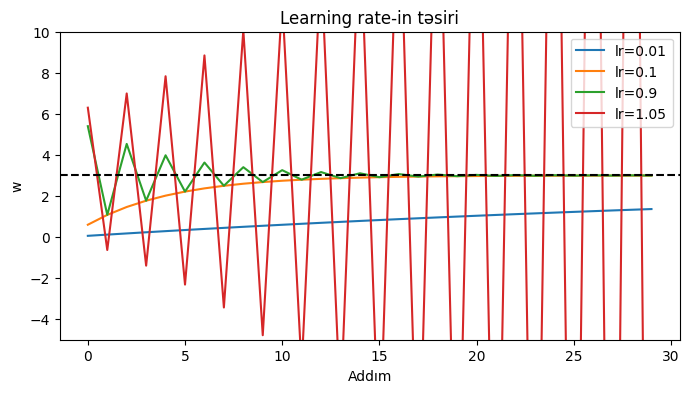

In [18]:
def run(lr, steps=30):
    w = torch.tensor(0.0, requires_grad=True)
    opt = torch.optim.SGD([w], lr=lr)
    history = []
    for step in range(steps):
        opt.zero_grad()
        loss = (w - 3) ** 2
        loss.backward()
        opt.step()
        history.append(w.item())
    return history


plt.figure(figsize=(8, 4))
for lr in [0.01, 0.1, 0.9, 1.05]:
    plt.plot(run(lr), label=f"lr={lr}")
plt.axhline(3, color="black", linestyle="--")
plt.ylim(-5, 10)
plt.xlabel("Addım")
plt.ylabel("w")
plt.title("Learning rate-in təsiri")
plt.legend()
plt.show()

`lr=0.01` yavaş gedir, `lr=0.1` yaxşıdır, `lr=0.9` minimumun ətrafında salınır, `lr=1.05` isə uzaqlaşır (diverge).

# Hamısı birlikdə - kiçik təsnifat modeli

3 sinifli süni data, `Net` modeli, `CrossEntropyLoss` və iki optimizer-in müqayisəsi.

torch.Size([600, 2]) torch.Size([600])


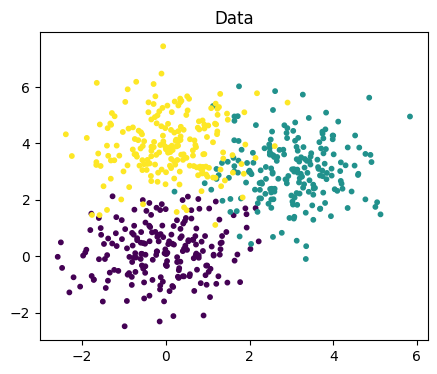

In [19]:
torch.manual_seed(42)
n = 200
centers = torch.tensor([[0.0, 0.0], [3.0, 3.0], [0.0, 4.0]])

X = torch.cat([torch.randn(n, 2) + c for c in centers])
y = torch.cat([torch.full((n,), i) for i in range(3)])
print(X.shape, y.shape)

plt.figure(figsize=(5, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis", s=10)
plt.title("Data")
plt.show()

In [20]:
def train(optimizer_name, lr, epochs=100):
    torch.manual_seed(42)
    model = Net(2, 16, 3)
    criterion = nn.CrossEntropyLoss()

    if optimizer_name == "SGD":
        optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    losses = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        out = model(X)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    with torch.no_grad():
        acc = (model(X).argmax(dim=1) == y).float().mean().item()

    return model, losses, acc

SGD:  loss=0.2258, accuracy=0.917
Adam: loss=0.1712, accuracy=0.925


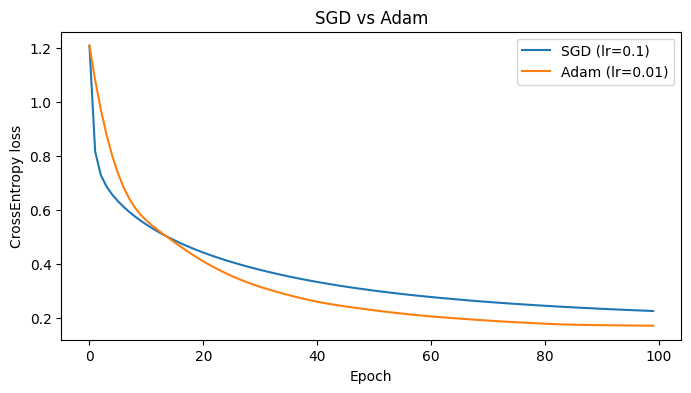

In [21]:
model_sgd, loss_sgd, acc_sgd = train("SGD", lr=0.1)
model_adam, loss_adam, acc_adam = train("Adam", lr=0.01)

print(f"SGD:  loss={loss_sgd[-1]:.4f}, accuracy={acc_sgd:.3f}")
print(f"Adam: loss={loss_adam[-1]:.4f}, accuracy={acc_adam:.3f}")

plt.figure(figsize=(8, 4))
plt.plot(loss_sgd, label="SGD (lr=0.1)")
plt.plot(loss_adam, label="Adam (lr=0.01)")
plt.xlabel("Epoch")
plt.ylabel("CrossEntropy loss")
plt.title("SGD vs Adam")
plt.legend()
plt.show()

In [22]:
sample = torch.tensor([[2.8, 3.2]])

with torch.no_grad():
    logits = model_adam(sample)
    probs = F.softmax(logits, dim=1)

print("Logit:", logits)
print("Ehtimallar:", probs)
print("Sinif:", probs.argmax(dim=1).item())

Logit: tensor([[-3.1053,  3.5043, -1.0130]])
Ehtimallar: tensor([[0.0013, 0.9879, 0.0108]])
Sinif: 1


# Anlayışlar arasında əlaqə

**Data → forward (nn.Module) → logit → softmax → ehtimal → loss → backward → gradient → optimizer.step() → yeni çəkilər**

| Anlayış | Nə edir |
|---|---|
| `nn.Module` | modelin baza sinfi, qatları və `forward`-u saxlayır |
| `nn.Linear` | $y = xW^T + b$, öyrədilən çəkilər |
| `forward()` | girişdən çıxışa hesablama |
| Softmax | logit-ləri ehtimala çevirir |
| Loss | səhvi bir ədədlə ölçür |
| `loss.backward()` | gradientləri hesablayır |
| Optimizer | gradientlərlə çəkiləri yeniləyir |
| Learning rate | addımın ölçüsü |

**Qısa suallar və cavablar:**
- *MSELoss-u təsnifatda niyə istifadə etmirik?* - Ehtimallar üçün zəif gradient verir, CrossEntropy səhv inamı daha güclü cəzalandırır.
- *BCELoss ilə CrossEntropyLoss fərqi?* - BCE 2 sinif (1 çıxış, sigmoid), CrossEntropy C sinif (C çıxış, softmax).
- *Niyə modelin sonunda softmax yazmırıq?* - `CrossEntropyLoss` özü log-softmax edir.
- *zero_grad() unudulsa nə olar?* - Gradientlər toplanır, addımlar səhv və böyük olur.
- *backward() və step() fərqi?* - backward gradienti hesablayır, step parametri dəyişir.
- *Learning rate çox böyük olsa?* - Loss salınır və ya artır, model öyrənmir.